# Amazon Sales Status Prediction (Multinomial Classification) - ANN

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/Users/sudharsank/AIML/datasets/Amazon Sale Report.csv')

/var/folders/7b/5_gy8f1j7171y56xbfvy4r7h0000gn/T/ipykernel_41052/308536185.py:1: DtypeWarning: Columns (23: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/Users/sudharsank/AIML/datasets/Amazon Sale Report.csv')


In [3]:
df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [4]:
df['Status'].unique()

<StringArray>
[                    'Cancelled',  'Shipped - Delivered to Buyer',
                       'Shipped',  'Shipped - Returned to Seller',
   'Shipped - Rejected by Buyer',     'Shipped - Lost in Transit',
    'Shipped - Out for Delivery', 'Shipped - Returning to Seller',
           'Shipped - Picked Up',                       'Pending',
 'Pending - Waiting for Pick Up',             'Shipped - Damaged',
                      'Shipping']
Length: 13, dtype: str

In [5]:
df.shape

(128975, 24)

In [6]:
df.columns

Index(['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ',
       'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city',
       'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids',
       'B2B', 'fulfilled-by', 'Unnamed: 22'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [8]:
df.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
Unnamed: 22           49050
dtype: int64

In [9]:
df['Courier Status'].unique()

<StringArray>
[nan, 'Shipped', 'Cancelled', 'Unshipped']
Length: 4, dtype: str

In [10]:
df['Courier Status'] = df['Courier Status'].fillna(df['Courier Status'].mode()[0])
df['currency'] = df['currency'].fillna(df['currency'].mode()[0])
df['Amount'] = df['Amount'].fillna(df['Amount'].mean())
df['ship-city'] = df['ship-city'].fillna(df['ship-city'].mode()[0])
df['ship-state'] = df['ship-state'].fillna(df['ship-state'].mode()[0])
df['ship-postal-code'] = df['ship-postal-code'].fillna(df['ship-postal-code'].mode()[0])
df['ship-country'] = df['ship-country'].fillna(df['ship-country'].mode()[0])
df['promotion-ids'] = df['promotion-ids'].fillna('None')
df['fulfilled-by'] = df['fulfilled-by'].fillna('Unknown')
df['Unnamed: 22'] = df['Unnamed: 22'].fillna(True)

In [11]:
df.isnull().sum()

index                 0
Order ID              0
Date                  0
Status                0
Fulfilment            0
Sales Channel         0
ship-service-level    0
Style                 0
SKU                   0
Category              0
Size                  0
ASIN                  0
Courier Status        0
Qty                   0
currency              0
Amount                0
ship-city             0
ship-state            0
ship-postal-code      0
ship-country          0
promotion-ids         0
B2B                   0
fulfilled-by          0
Unnamed: 22           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.rename(columns={
    'Order ID': 'Order_ID',
    'Sales Channel ': 'Sales_Channel',
    'ship-service-level': 'ship_service_level',
    'Courier Status': 'Courier_Status',
    'ship-city': 'ship_city',
    'ship-state': 'ship_state',
    'ship-postal-code': 'ship_postal_code',
    'ship-country': 'ship_country',
    'promotion-ids': 'promotion_ids',
    'fulfilled-by': 'fulfilled_by',
    'Unnamed: 22': 'Unnamed_22',
})

In [14]:
cat_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()
cat_cols.remove('Status')
cat_cols

/var/folders/7b/5_gy8f1j7171y56xbfvy4r7h0000gn/T/ipykernel_41052/3014397330.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()


['Order_ID',
 'Date',
 'Fulfilment',
 'Sales_Channel',
 'ship_service_level',
 'Style',
 'SKU',
 'Category',
 'Size',
 'ASIN',
 'Courier_Status',
 'currency',
 'ship_city',
 'ship_state',
 'ship_country',
 'promotion_ids',
 'B2B',
 'fulfilled_by',
 'Unnamed_22']

In [15]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Order_ID'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status               Cancelled  Pending  Pending - Waiting for Pick Up  \
Order_ID                                                                 
171-0000547-8192359          0        0                              0   
171-0000902-4490745          1        0                              0   
171-0001409-6228339          0        0                              0   
171-0003082-5110755          0        0                              0   
171-0003738-2052324          0        0                              0   
...                        ...      ...                            ...   
S02-9578181-3610412          0        0                              0   
S02-9599483-2736812          0        0                              0   
S02-9649067-3246849          0        0                              0   
S02-9736323-0094708          0        0                              0   
S02-9878098-5959538          0        0                              0   

Status               Shipped  Shipped

In [16]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Date'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status    Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Date                                                                   
03-31-22         18        0                              0      136   
04-01-22        234        0                              0      975   
04-02-22        256        0                              0     1040   
04-03-22        241        0                              0     1115   
04-04-22        198        1                              0      949   
...             ...      ...                            ...      ...   
06-25-22        129        5                              0      681   
06-26-22        158       18                              0      758   
06-27-22        140       21                             29      660   
06-28-22        162      131                            252      665   
06-29-22         31      454                              0      173   

Status    Shipped - Damaged  Shipped - Delivered to Buyer  \
Da

In [17]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Fulfilment'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status      Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Fulfilment                                                               
Amazon          11471      415                              0    77804   
Merchant         6861      243                            281        0   

Status      Shipped - Damaged  Shipped - Delivered to Buyer  \
Fulfilment                                                    
Amazon                      0                             0   
Merchant                    1                         28769   

Status      Shipped - Lost in Transit  Shipped - Out for Delivery  \
Fulfilment                                                          
Amazon                              0                           0   
Merchant                            5                          35   

Status      Shipped - Picked Up  Shipped - Rejected by Buyer  \
Fulfilment                                                     
Amazon                        0              

In [18]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Sales_Channel'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status         Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Sales_Channel                                                               
Amazon.in          18331      658                            281    77689   
Non-Amazon             1        0                              0      115   

Status         Shipped - Damaged  Shipped - Delivered to Buyer  \
Sales_Channel                                                    
Amazon.in                      1                         28769   
Non-Amazon                     0                             0   

Status         Shipped - Lost in Transit  Shipped - Out for Delivery  \
Sales_Channel                                                          
Amazon.in                              5                          35   
Non-Amazon                             0                           0   

Status         Shipped - Picked Up  Shipped - Rejected by Buyer  \
Sales_Channel                                                     
Ama

In [19]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['ship_service_level'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status              Cancelled  Pending  Pending - Waiting for Pick Up  \
ship_service_level                                                      
Expedited               11423      413                              0   
Standard                 6909      245                            281   

Status              Shipped  Shipped - Damaged  Shipped - Delivered to Buyer  \
ship_service_level                                                             
Expedited             76779                  0                             0   
Standard               1025                  1                         28769   

Status              Shipped - Lost in Transit  Shipped - Out for Delivery  \
ship_service_level                                                          
Expedited                                   0                           0   
Standard                                    5                          35   

Status              Shipped - Picked Up  Shipped - Rejected by Buyer  \
ship_

In [20]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Style'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status  Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Style                                                                
AN201           0        0                              0        3   
AN202           0        0                              0        5   
AN203           0        0                              0        0   
AN204           3        0                              0        1   
AN205           1        0                              0        5   
...           ...      ...                            ...      ...   
SET445          0        0                              0        0   
SET446          0        0                              0        0   
SET449          0        0                              0        0   
SET461          1        0                              0        3   
SET462          0        0                              0        0   

Status  Shipped - Damaged  Shipped - Delivered to Buyer  \
Style                         

In [21]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['SKU'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status            Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
SKU                                                                            
AN201-RED-M               0        0                              0        1   
AN201-RED-XL              0        0                              0        2   
AN201-RED-XXL             0        0                              0        0   
AN202-ORANGE-M            0        0                              0        0   
AN202-ORANGE-S            0        0                              0        4   
...                     ...      ...                            ...      ...   
SET449-KR-NP-S            0        0                              0        0   
SET461-KR-NP-XL           0        0                              0        1   
SET461-KR-NP-XS           0        0                              0        1   
SET461-KR-NP-XXL          1        0                              0        1   
SET462-KR-NP-S            0        0    

In [22]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Category'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status         Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Category                                                                    
Blouse               116        3                              1      623   
Bottom                60        1                              2      222   
Dupatta                0        0                              0        3   
Ethnic Dress         145        7                              0      755   
Saree                 21        0                              0      119   
Set                 7337      252                            108    30665   
Top                 1276       55                             19     7143   
Western Dress       2122       92                             79     7480   
kurta               7255      248                             72    30794   

Status         Shipped - Damaged  Shipped - Delivered to Buyer  \
Category                                                         
Blouse              

In [23]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Size'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status  Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Size                                                                 
3XL          1865       64                             32     8924   
4XL            48        3                              0      286   
5XL            55        3                              1      388   
6XL            72        5                              2      492   
Free           49        1                              0      259   
L            3145      122                             41    13059   
M            3375      125                             51    13303   
S            2592       75                             29    10486   
XL           2850      117                             51    12439   
XS           1864       54                             25     7066   
XXL          2417       89                             49    11102   

Status  Shipped - Damaged  Shipped - Delivered to Buyer  \
Size                          

In [24]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['ASIN'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status      Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
ASIN                                                                     
B01LYC0N7Q          3        1                              0        3   
B01LYC0NV1          2        0                              0       10   
B01LZMXYSV          3        0                              0        5   
B01LZYQ93J          4        0                              0        4   
B01M0LXTZE          2        0                              0        7   
...               ...      ...                            ...      ...   
B0B4992J2M          0        0                              0        0   
B0B4994HY6          0        0                              0        0   
B0B499JD9S          0        0                              0        0   
B0B49CGL99          0        0                              0        0   
B0B4GDJ9MK          0        0                              0        0   

Status      Shipped - Damaged  Shippe

In [25]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Courier_Status'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status          Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Courier_Status                                                               
Cancelled            5840        2                              0       93   
Shipped              6861       10                              0    77596   
Unshipped            5631      646                            281      115   

Status          Shipped - Damaged  Shipped - Delivered to Buyer  \
Courier_Status                                                    
Cancelled                       0                             0   
Shipped                         1                         28769   
Unshipped                       0                             0   

Status          Shipped - Lost in Transit  Shipped - Out for Delivery  \
Courier_Status                                                          
Cancelled                               0                           0   
Shipped                                 5             

In [26]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['currency'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status    Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
currency                                                               
INR           18332      658                            281    77804   

Status    Shipped - Damaged  Shipped - Delivered to Buyer  \
currency                                                    
INR                       1                         28769   

Status    Shipped - Lost in Transit  Shipped - Out for Delivery  \
currency                                                          
INR                               5                          35   

Status    Shipped - Picked Up  Shipped - Rejected by Buyer  \
currency                                                     
INR                       973                           11   

Status    Shipped - Returned to Seller  Shipped - Returning to Seller  \
currency                                                                
INR                               1953                          

In [27]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['ship_city'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status                                          Cancelled  Pending  \
ship_city                                                            
(Chikmagalur disterict).     (N.R pur thaluku)          0        0   
(Via Cuncolim)Quepem,South Goa                          0        0   
,HYDERABAD                                              0        0   
,raibarely road faizabad (Ayodhya)                      0        0   
..katra                                                 0        0   
...                                                   ...      ...   
yavatmal                                                0        0   
yazali                                                  0        1   
yellapur                                                0        0   
zirakpur                                                1        0   
लखनऊ                                                    0        0   

Status                                          Pending - Waiting for Pick Up  \
ship_cit

In [28]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['ship_state'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status              Cancelled  Pending  Pending - Waiting for Pick Up  \
ship_state                                                              
ANDAMAN & NICOBAR          45        2                              3   
ANDHRA PRADESH            892       25                             16   
APO                         1        0                              0   
AR                          0        0                              0   
ARUNACHAL PRADESH          19        1                              1   
...                       ...      ...                            ...   
goa                         0        0                              0   
orissa                      0        0                              0   
punjab                      1        0                              0   
rajasthan                   0        0                              0   
rajsthan                    0        0                              0   

Status              Shipped  Shipped - Damaged  Sh

In [29]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['ship_country'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status        Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
ship_country                                                               
IN                18332      658                            281    77804   

Status        Shipped - Damaged  Shipped - Delivered to Buyer  \
ship_country                                                    
IN                            1                         28769   

Status        Shipped - Lost in Transit  Shipped - Out for Delivery  \
ship_country                                                          
IN                                    5                          35   

Status        Shipped - Picked Up  Shipped - Rejected by Buyer  \
ship_country                                                     
IN                            973                           11   

Status        Shipped - Returned to Seller  Shipped - Returning to Seller  \
ship_country                                                                
IN      

In [30]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['promotion_ids'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status                                              Cancelled  Pending  \
promotion_ids                                                            
Amazon PLCC Free-Financing Universal Merchant A...          0        0   
Amazon PLCC Free-Financing Universal Merchant A...          0        0   
Amazon PLCC Free-Financing Universal Merchant A...          0        0   
Amazon PLCC Free-Financing Universal Merchant A...          0        0   
Amazon PLCC Free-Financing Universal Merchant A...          0        0   
...                                                       ...      ...   
VPC-44571-41445527 Coupon                                   0        0   
VPC-44571-41445561 Coupon                                   0        0   
VPC-44571-44201687 Coupon                                   0        0   
VPC-44571-44201770 Coupon                                   0        0   
VPC-44571-44201853 Coupon                                   0        0   

Status                               

In [31]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['B2B'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status  Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
B2B                                                                  
False       18259      654                            281    77273   
True           73        4                              0      531   

Status  Shipped - Damaged  Shipped - Delivered to Buyer  \
B2B                                                       
False                   1                         28520   
True                    0                           249   

Status  Shipped - Lost in Transit  Shipped - Out for Delivery  \
B2B                                                             
False                           5                          35   
True                            0                           0   

Status  Shipped - Picked Up  Shipped - Rejected by Buyer  \
B2B                                                        
False                   968                           11   
True                      5              

In [32]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['fulfilled_by'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status        Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
fulfilled_by                                                               
Easy Ship          6861      243                            281        0   
Unknown           11471      415                              0    77804   

Status        Shipped - Damaged  Shipped - Delivered to Buyer  \
fulfilled_by                                                    
Easy Ship                     1                         28769   
Unknown                       0                             0   

Status        Shipped - Lost in Transit  Shipped - Out for Delivery  \
fulfilled_by                                                          
Easy Ship                             5                          35   
Unknown                               0                           0   

Status        Shipped - Picked Up  Shipped - Rejected by Buyer  \
fulfilled_by                                                     
Easy Ship        

In [33]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Unnamed_22'], df['Status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')

Status      Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Unnamed_22                                                               
False           11208      657                            281    48854   
True             7124        1                              0    28950   

Status      Shipped - Damaged  Shipped - Delivered to Buyer  \
Unnamed_22                                                    
False                       1                         16702   
True                        0                         12067   

Status      Shipped - Lost in Transit  Shipped - Out for Delivery  \
Unnamed_22                                                          
False                               3                          34   
True                                2                           1   

Status      Shipped - Picked Up  Shipped - Rejected by Buyer  \
Unnamed_22                                                     
False                       969              

In [34]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols

['index', 'Qty', 'Amount', 'ship_postal_code']

In [35]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'index ~ C(Status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                 df        sum_sq       mean_sq           F  PR(>F)
C(Status)      12.0  2.898420e+12  2.415350e+11  177.094393     0.0
Residual   128962.0  1.758883e+14  1.363877e+09         NaN     NaN
C(Status)     True
Residual     False
Name: PR(>F), dtype: bool


In [36]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Qty ~ C(Status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                 df       sum_sq     mean_sq             F  PR(>F)
C(Status)      12.0  7587.057634  632.254803  16060.170639     0.0
Residual   128962.0  5076.959997    0.039368           NaN     NaN
C(Status)     True
Residual     False
Name: PR(>F), dtype: bool


In [37]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Amount ~ C(Status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                 df        sum_sq        mean_sq         F        PR(>F)
C(Status)      12.0  3.894295e+06  324524.575168  4.369098  5.221474e-07
Residual   128962.0  9.578943e+09   74277.249148       NaN           NaN
C(Status)     True
Residual     False
Name: PR(>F), dtype: bool


In [38]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'ship_postal_code ~ C(Status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                 df        sum_sq       mean_sq         F        PR(>F)
C(Status)      12.0  3.751994e+12  3.126662e+11  8.532083  1.927939e-16
Residual   128962.0  4.725933e+15  3.664594e+10       NaN           NaN
C(Status)     True
Residual     False
Name: PR(>F), dtype: bool


In [39]:
df.shape

(128975, 24)

In [40]:
df = df.drop(['currency', 'ship_country'], axis=1)

In [41]:
df.shape

(128975, 22)

In [42]:
df

,index,Order_ID,Date,Status,Fulfilment,Sales_Channel,ship_service_level,Style,SKU,Category,...,Courier_Status,Qty,Amount,ship_city,ship_state,ship_postal_code,promotion_ids,B2B,fulfilled_by,Unnamed_22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,Shipped,0,647.62,MUMBAI,MAHARASHTRA,400081.0,None,False,Easy Ship,True
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,Shipped,1,406.00,BENGALURU,KARNATAKA,560085.0,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,True
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,Shipped,1,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN Core Free Shipping 2015/04/08 23-48-5-108,True,Unknown,True
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,Shipped,0,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,None,False,Easy Ship,True
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,Shipped,1,574.00,CHENNAI,TAMIL NADU,600073.0,None,False,Unknown,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128970,128970,406-6001380-7673107,05-31-22,Shipped,Amazon,Amazon.in,Expedited,JNE3697,JNE3697-KR-XL,kurta,...,Shipped,1,517.00,HYDERABAD,TELANGANA,500013.0,None,False,Unknown,False
128971,128971,402-9551604-7544318,05-31-22,Shipped,Amazon,Amazon.in,Expedited,SET401,SET401-KR-NP-M,Set,...,Shipped,1,999.00,GURUGRAM,HARYANA,122004.0,IN Core Free Shipping 2015/04/08 23-48-5-108,False,Unknown,False
128972,128972,407-9547469-3152358,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0157,J0157-DR-XXL,Western Dress,...,Shipped,1,690.00,HYDERABAD,TELANGANA,500049.0,None,False,Unknown,False
128973,128973,402-6184140-0545956,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0012,J0012-SKD-XS,Set,...,Shipped,1,1199.00,Halol,Gujarat,389350.0,IN Core Free Shipping 2015/04/08 23-48-5-108,False,Unknown,False


In [43]:
# df['Status'].value_counts()

In [44]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# sns.countplot(x='Status', data=df)

In [45]:
# Sampling is not applied because the original class distribution is preserved.

In [46]:
df.columns

Index(['index', 'Order_ID', 'Date', 'Status', 'Fulfilment', 'Sales_Channel',
       'ship_service_level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier_Status', 'Qty', 'Amount', 'ship_city', 'ship_state',
       'ship_postal_code', 'promotion_ids', 'B2B', 'fulfilled_by',
       'Unnamed_22'],
      dtype='str')

In [47]:
df.shape

(128975, 22)

In [48]:
from sklearn.preprocessing import OrdinalEncoder
o = OrdinalEncoder()
df[['index']] = o.fit_transform(df[['index']])
df[['Order_ID']] = o.fit_transform(df[['Order_ID']])
df[['Date']] = o.fit_transform(df[['Date']])
df[['Fulfilment']] = o.fit_transform(df[['Fulfilment']])
df[['Sales_Channel']] = o.fit_transform(df[['Sales_Channel']])
df[['ship_service_level']] = o.fit_transform(df[['ship_service_level']])
df[['Style']] = o.fit_transform(df[['Style']])
df[['SKU']] = o.fit_transform(df[['SKU']])
df[['Category']] = o.fit_transform(df[['Category']])
df[['Size']] = o.fit_transform(df[['Size']])
df[['ASIN']] = o.fit_transform(df[['ASIN']])
df[['Courier_Status']] = o.fit_transform(df[['Courier_Status']])
df[['Qty']] = o.fit_transform(df[['Qty']])
df[['Amount']] = o.fit_transform(df[['Amount']])
df[['ship_city']] = o.fit_transform(df[['ship_city']])
df[['ship_state']] = o.fit_transform(df[['ship_state']])
df[['ship_postal_code']] = o.fit_transform(df[['ship_postal_code']])
df[['promotion_ids']] = o.fit_transform(df[['promotion_ids']])
df[['B2B']] = o.fit_transform(df[['B2B']])
df[['fulfilled_by']] = o.fit_transform(df[['fulfilled_by']])
df[['Unnamed_22']] = o.fit_transform(df[['Unnamed_22']])

In [49]:
from sklearn.preprocessing import LabelEncoder
o = LabelEncoder()
df['Status'] = o.fit_transform(df['Status'])

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  float64
 1   Order_ID            128975 non-null  float64
 2   Date                128975 non-null  float64
 3   Status              128975 non-null  int64  
 4   Fulfilment          128975 non-null  float64
 5   Sales_Channel       128975 non-null  float64
 6   ship_service_level  128975 non-null  float64
 7   Style               128975 non-null  float64
 8   SKU                 128975 non-null  float64
 9   Category            128975 non-null  float64
 10  Size                128975 non-null  float64
 11  ASIN                128975 non-null  float64
 12  Courier_Status      128975 non-null  float64
 13  Qty                 128975 non-null  float64
 14  Amount              128975 non-null  float64
 15  ship_city           128975 non-null  float64


In [51]:
x = df.drop('Status', axis=1)
y = df['Status']

In [52]:
from sklearn.model_selection import train_test_split
x_samp_train, x_samp_test, y_samp_train, y_samp_test = train_test_split(x, y, test_size=0.20,random_state=42)
print(x_samp_train.shape)
print(x_samp_test.shape)
print(y_samp_train.shape)
print(y_samp_test.shape)

(103180, 21)
(25795, 21)
(103180,)
(25795,)


In [53]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Align split variable names used by the ANN
x_train = x_samp_train
x_test = x_samp_test
y_train = y_samp_train
y_test = y_samp_test

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaling Done!")
print("x_train_scaled shape:", x_train_scaled.shape)

Scaling Done!
x_train_scaled shape: (103180, 21)


In [54]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

# Build and compile the ANN model for multiclass classification.
n_classes = len(np.unique(y))

model = Sequential([
    Dense(500, activation='relu', input_shape=(x_train_scaled.shape[1],)),
    Dense(300, activation='relu'),
    Dense(150, activation='relu'),
    Dense(n_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train_scaled,
    y_train,
    epochs=10,
    validation_data=(x_test_scaled, y_test)
)

Epoch 1/10


/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3225/3225 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step - accuracy: 0.9710 - loss: 0.1083 - val_accuracy: 0.9748 - val_loss: 0.0897
Epoch 2/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9752 - loss: 0.0899 - val_accuracy: 0.9755 - val_loss: 0.0882
Epoch 3/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9763 - loss: 0.0870 - val_accuracy: 0.9749 - val_loss: 0.0912
Epoch 4/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9764 - loss: 0.0853 - val_accuracy: 0.9740 - val_loss: 0.0881
Epoch 5/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9764 - loss: 0.0857 - val_accuracy: 0.9758 - val_loss: 0.0930
Epoch 6/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9767 - loss: 0.0838 - val_accuracy: 0.9758 - val_loss: 0.0869
Epoch 7/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9774 - loss: 0.0824 - val_accuracy: 0.9741 - val_loss: 0.0924
Epoch 8/10
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9775 - loss: 0.0833 - val_accurac

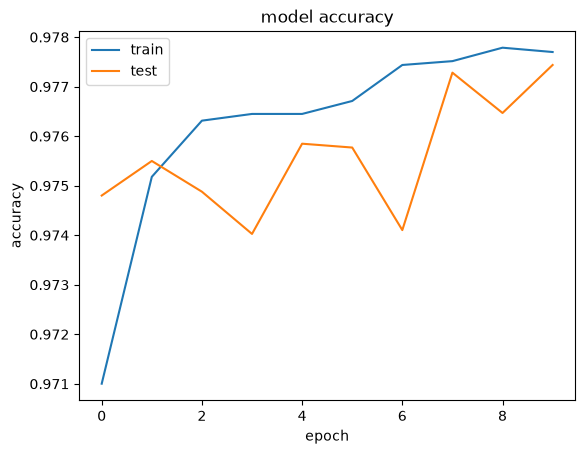

In [55]:
# Plot Model Accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

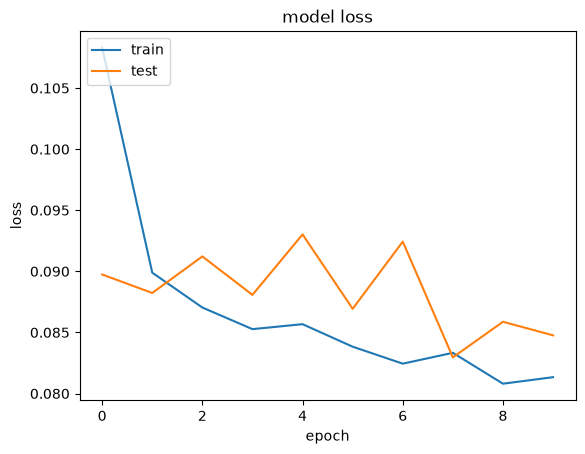

In [56]:
# Plot Model Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()